## Current branch and cached evidence

This notebook executes bounded CPU smoke checks. Scientific plots below retain their original saved source, settings and qualification scope; they are not fits from this smoke run. The current independent production/testing default is **128 walkers /128 burn-in /256 retained, one ensemble**, with 2,048 draws for deterministic trend integration. Qualification still uses independent ensembles and diagnostic gates. See [VALIDATION_STATUS.md](VALIDATION_STATUS.md) and [EXECUTION_PROFILES.md](EXECUTION_PROFILES.md).

All six preset families have CPU/native MPS likelihood and trend-smoother checks. GPU production uses float32 automatically; CUDA hardware testing is pending. Historical float32 failures and short joint convergence flags remain. The affine API now composes supported components; legacy names remain compatible. See [COMPONENTS.md](COMPONENTS.md). Panel limits and the separate spatial/lag runtime-estimate and selection gates remain in force. No cached selection enables a new long fit automatically.

Timing charts in the older stage04 sections describe that historical implementation, before the structured GPU backend. Current measured CPU/GPU production timings are in [VALIDATION_STATUS.md](VALIDATION_STATUS.md).

In [1]:
from pathlib import Path
import hashlib, json
from dlmmc import PRODUCTION_PROFILE
current_bundle = Path.cwd() / "examples/modernization/current"
current_manifest = json.loads((current_bundle / "manifest.json").read_text())
for filename, expected in current_manifest["files"].items():
    assert hashlib.sha256((current_bundle / filename).read_bytes()).hexdigest() == expected
print("Current production profile:", PRODUCTION_PROFILE.to_dict())
print("Verified cached follow-up evidence files:", len(current_manifest["files"]))

Current production profile: {'name': 'production', 'runs': 1, 'half_walkers': 64, 'warmup': 128, 'retained_sweeps': 256, 'chunk_sweeps': 16, 'thin': 1, 'output_draws_per_sweep': 8}
Verified cached follow-up evidence files: 8


/Users/justin/Documents/projects/dlmmc-modernization/reports/20-composition/env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Spatial sigma-trend priors

Only `sigma_trend` has a spatial prior: a Gaussian on the parameter itself, jointly truncated positive. All other parameter priors remain independent across panels. This changes the joint posterior; independent fits are an illustration, not an equality reference at nonzero coupling.

The source grid supplies pressure, not altitude. This example explicitly uses natural log-pressure distance and latitude in degrees north. The API also accepts altitude coordinates with explicit units. Means/scales below are in normalized-model units; physical sigma scales are panel-specific ozone ranges times these values. Lengths and prior hyperparameters are fixed during inference.

**Run All is bounded:** a four-cell, 12-month fresh smoke run, plus provenance-checked cached scientific results. It neither repeats the real pilot/tuning nor launches a selected fit. CPU64 is locally qualified; float32 is retained for research and fails the strict joint numerical gate. GPU posterior qualification remains pending.

In [2]:
from pathlib import Path
import json, hashlib, tempfile
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Image
from dlmmc import (prepare_data, GaussianSpatialPrior, test_lengths_from_correlation,
                   sample_spatial, resume_spatial, load_spatial, diagnose_spatial)
from dlmmc.examples import load_panels
repo = Path.cwd()
assert (repo / "examples/modernization/spatial").exists(), "Run from the DLMMC checkout"
bundle = repo / "examples/modernization/spatial"
y, uncertainty, predictors, provenance = load_panels(bundle)
assert y.sizes["panel"] == 4
print(provenance["panel_ids"])
print(y.coords)
evidence = json.loads((bundle / "evidence.json").read_text())
for name, record in evidence.items():
    assert hashlib.sha256((bundle / name).read_bytes()).hexdigest() == record["sha256"]
print("Checked cached evidence checksums; no reference sampling.")

['p10-lat04', 'p10-lat05', 'p11-lat04', 'p11-lat05']
Coordinates:
  * time      (time) datetime64[ns] 3kB 1985-01-15T12:00:00 ... 2017-12-15T12...
  * panel     (panel) <U9 144B 'p10-lat04' 'p10-lat05' 'p11-lat04' 'p11-lat05'
    pressure  (panel) float64 32B 21.54 21.54 17.78 17.78
    latitude  (panel) float64 32B -15.0 -5.0 -15.0 -5.0
Checked cached evidence checksums; no reference sampling.


## Lengths and the separate 0.5 test setup

Production callers supply Gaussian lengths directly. This fixture derives lengths from adjacent log-pressure/latitude spacings, then feeds the ordinary API. The target 0.5 is the underlying Gaussian kernel correlation. Joint positive truncation gives about 0.295 neighboring prior correlation in this fixture; posterior correlations may differ again. No GMRF, nugget, or post-truncation retuning is used.

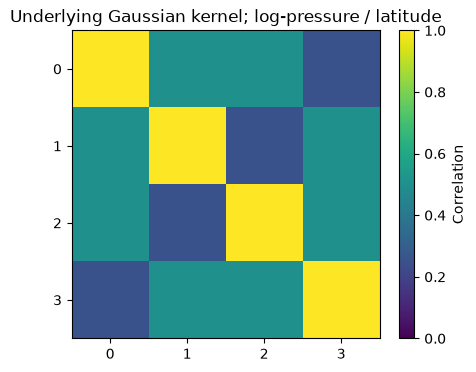

Lengths: 0.1629696363601444 dimensionless log-pressure ratio; 8.493218002880191 degrees latitude


In [3]:
config = json.loads((bundle / "prior.json").read_text())
z = np.log(y.pressure.values)
lat = y.latitude.values
length_z, length_lat = test_lengths_from_correlation(abs(z[0]-z[2]), abs(lat[0]-lat[1]), rho=0.5)
assert np.allclose([length_z, length_lat], [config["length_vertical"], config["length_latitude"]])
prior = GaussianSpatialPrior(**config)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(prior.correlation(), vmin=0, vmax=1)
ax.set(xticks=range(4), yticks=range(4), title="Underlying Gaussian kernel; log-pressure / latitude")
fig.colorbar(im, ax=ax, label="Correlation")
plt.show()
print("Lengths:", length_z, "dimensionless log-pressure ratio;", length_lat, "degrees latitude")

## Fresh bounded API smoke check

Four independent ensembles use tight full-rank clouds near an optimized point. The conditional schedule jointly updates the sigma field, then updates nuisance blocks conditional on that full field. Walkers are not independent chains, and spatial cells are not independent fits. The intentionally short result must remain inconclusive; reconstruction is forbidden here. The saved scientific example below has passed its separate posterior and reconstructed-output gates.

In [4]:
from dlmmc import Model
prepared = prepare_data(y.isel(time=slice(0,12)), predictors.isel(time=slice(0,12)),
                        uncertainty=uncertainty.isel(time=slice(0,12)), model=Model.from_preset("vanilla_ar1"), dtype="float64", device="cpu")
with tempfile.TemporaryDirectory(prefix="dlmmc-spatial-smoke-") as temporary:
    fit = sample_spatial(prepared, prior, output_dir=Path(temporary)/"fit", backend="numba",
                         half_walkers=20, runs=4, warmup=2, retained_sweeps=4,
                         chunk_sweeps=2, seed=2026113001, wall_seconds=60,
                         phase="pilot", update_schedule="field_local")
    fit = resume_spatial(fit.path, retained_sweeps=6, wall_seconds=60)
    restored = load_spatial(fit.path)
    posterior = restored.posterior()
    assert posterior.unconstrained.shape == (4,6,40,4,4)
    assert np.isfinite(posterior.unconstrained).all()
    diagnostics = diagnose_spatial(restored)
    assert not diagnostics["eligible"]
    print(posterior.sizes, diagnostics["status"])
print("Fresh smoke completed; no reconstructed scientific output generated.")

Frozen({'run': 4, 'draw': 6, 'walker': 40, 'cell': 4, 'parameter': 4}) INCONCLUSIVE
Fresh smoke completed; no reconstructed scientific output generated.


## Saved joint reference evidence

The following **48-month synthetic** four-cell comparison uses joint Stan, not independent fits. All 160 parameter/contrast/product metrics and 183 reconstructed metrics per panel passed practical MC-aware compatibility. One trend-SD point flag remains recorded. Rare near-unit-root draws needed additional conditional-state sampling; no MCMC draw was discarded. These results do not establish full-grid or real-data convergence.

The sigma plot is in normalized ozone units; physical units multiply each panel's saved ozone range. The prior illustration uses independent Gaussian proposals and keeps jointly positive vectors, not four independent half-normals.

,panel,status,metrics,affine_ESS,Stan_ESS,point_flags
0,s00,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,183,33365.388699,3497.696434,[sd:trend[12]]
1,s01,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,183,35696.521814,3202.165459,[]
2,s10,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,183,36415.986693,3805.651328,[]
3,s11,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,183,37131.665458,2731.160119,[]


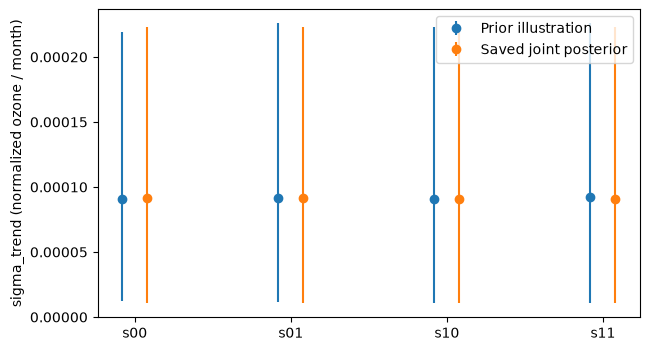

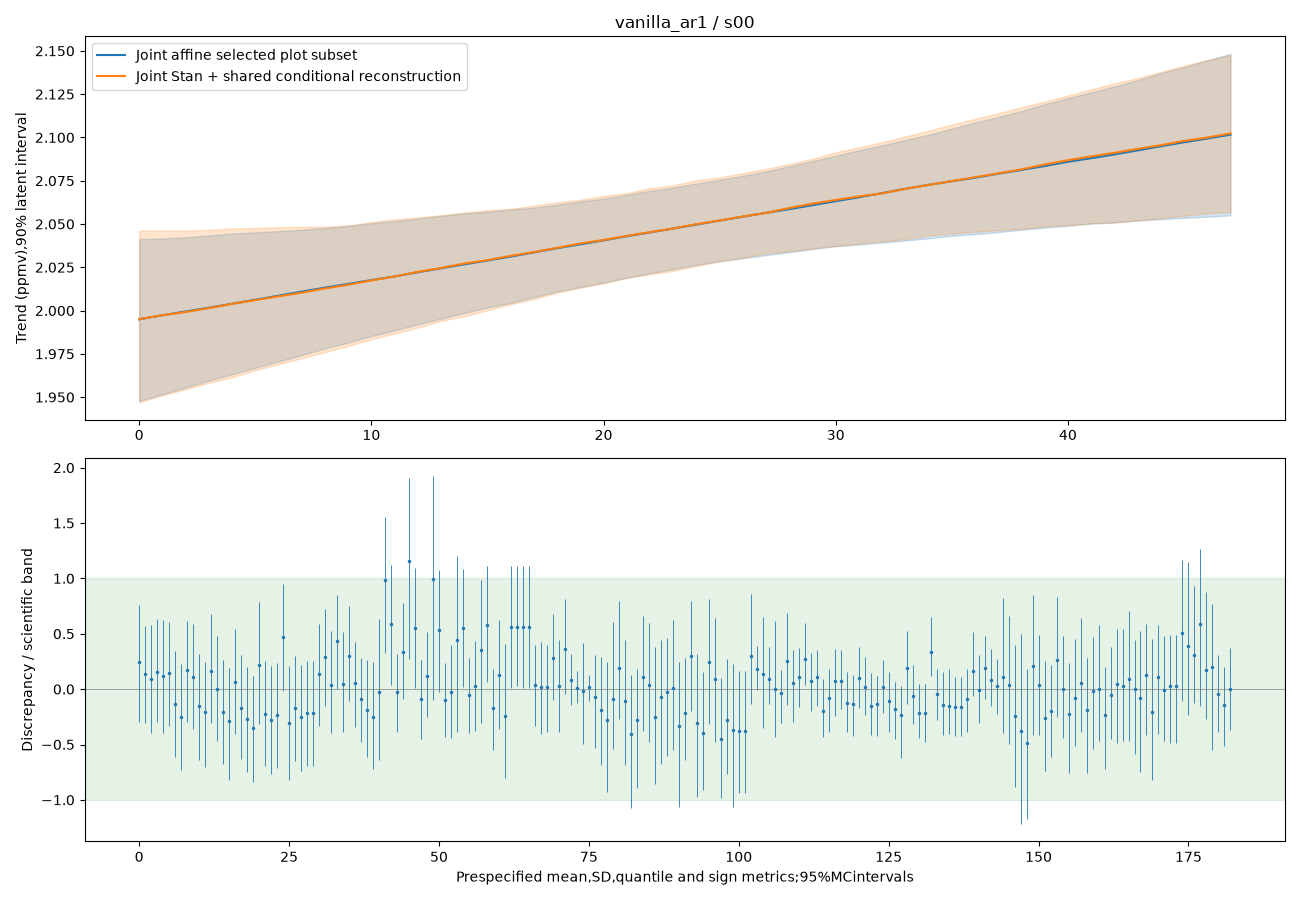

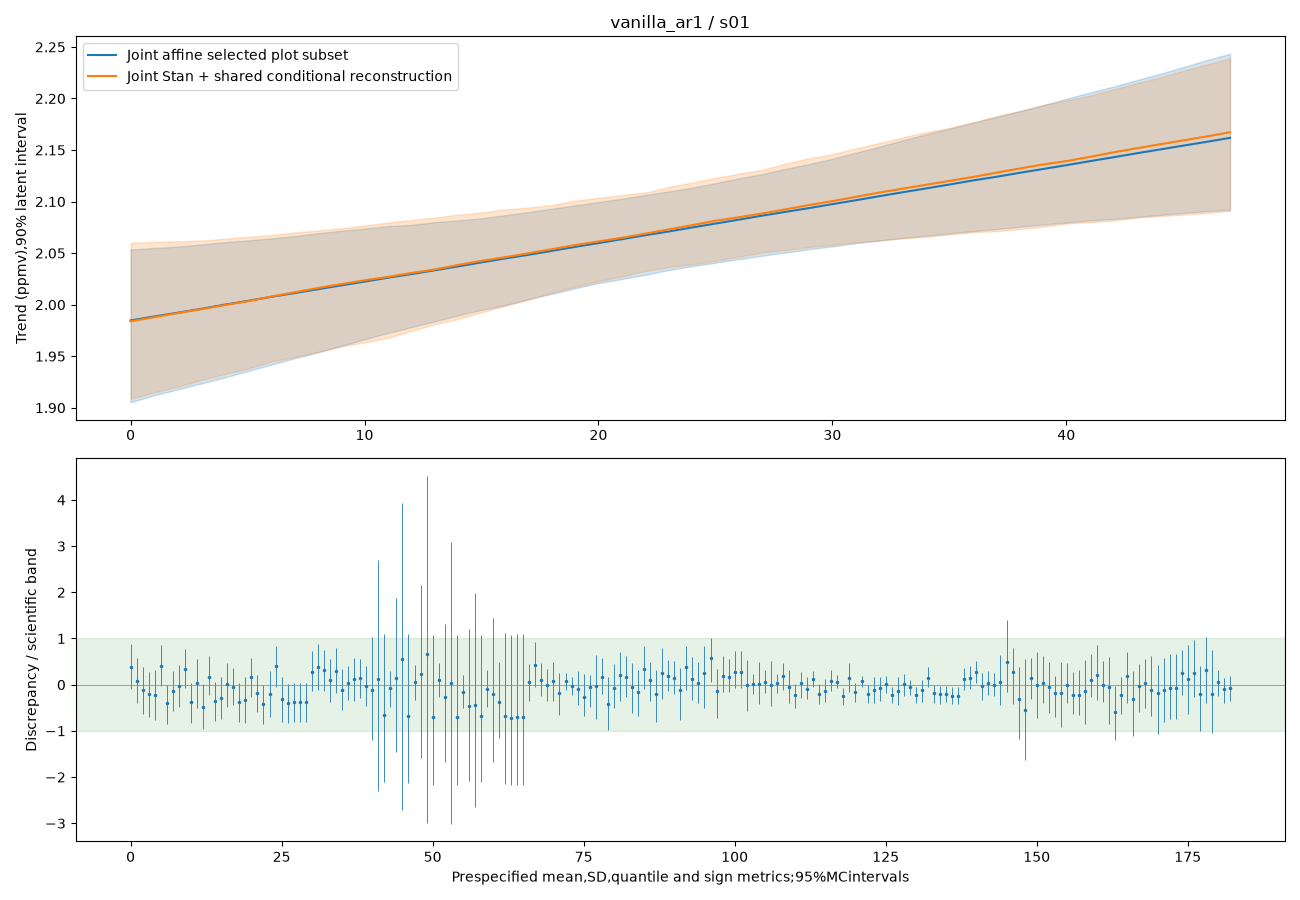

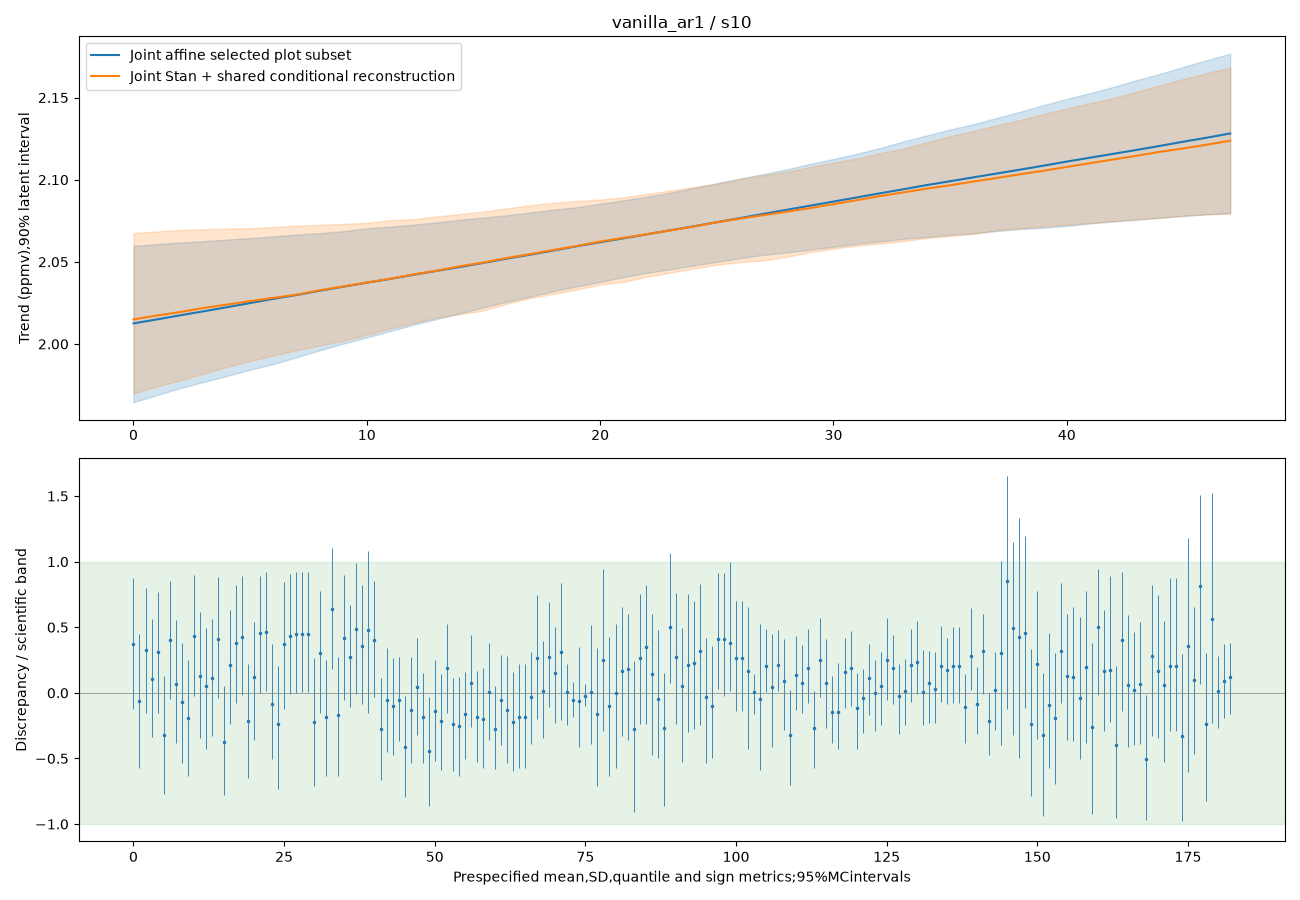

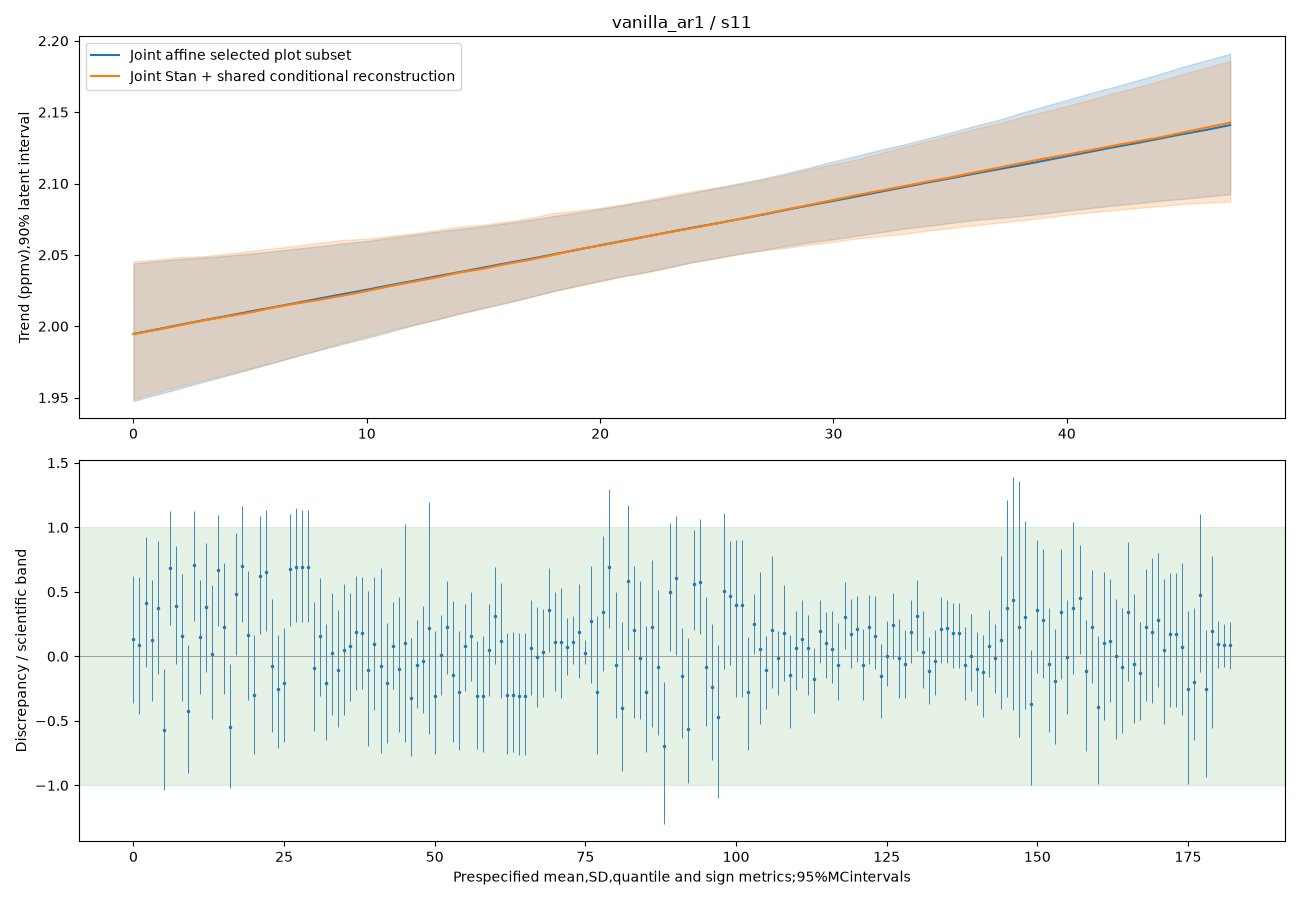

In [5]:
joint = json.loads((bundle/"05-joint-posterior-comparison.json").read_text())
rows=[]
for panel in ["s00","s01","s10","s11"]:
    result=json.loads((bundle/f"05-scientific-vanilla_ar1-{panel}-v4.json").read_text())
    rows.append(dict(panel=panel,status=result["status"],metrics=len(result["quantities"]),
                     affine_ESS=result["minimum_ess"]["affine"],Stan_ESS=result["minimum_ess"]["reference"],
                     point_flags=result["point_flags"]))
display(pd.DataFrame(rows))
with np.load(bundle/"synthetic-sigma-summary.npz") as zfile:
    quant=zfile["quantiles"]
rng=np.random.default_rng(2026113002)
raw=rng.multivariate_normal(np.zeros(4),prior.correlation(),size=10000)*1e-4
positive=raw[np.all(raw>0,axis=1)]
prior_q=np.quantile(positive,[.05,.5,.95],axis=0)
fig,ax=plt.subplots(figsize=(7,4))
for q,label,shift in [(prior_q,"Prior illustration",-.08),(quant,"Saved joint posterior",.08)]:
    ax.errorbar(np.arange(4)+shift,q[1],yerr=[q[1]-q[0],q[2]-q[1]],fmt="o",label=label)
ax.set(xticks=range(4),xticklabels=["s00","s01","s10","s11"],ylabel="sigma_trend (normalized ozone / month)")
ax.legend();plt.show()
for panel in ["s00","s01","s10","s11"]:
    display(Image(filename=str(bundle/f"05-scientific-vanilla_ar1-{panel}-v4.png")))

## Pilot, runtime estimate, then selection

The measured real 2×2 pilot uses 396 monthly observations. Inspect its counts and mixing limitations before choosing a workload. Compilation/disposable warmup are separate; initialization and MCMC warmup count toward time-to-ESS. Operational caps count actual wall time, including the recorded interruption/overrun. The fixed-budget projections are not promises of convergence. Full-grid diagnostics currently materialize pairwise summaries and cannot fit this laptop's memory.

A post-pilot run requires the explicit stage-05 selection record, even for four panels. It is disabled by default. The selected fit and independent-versus-coupled illustration are shown below as saved qualified results. No uncoupled-equality claim is made for nonzero correlation.

In [6]:
runtime=json.loads((bundle/"05-spatial-runtime-estimate.json").read_text())
tuning=json.loads((bundle/"05-sampler-tuning.json").read_text())
display(runtime)
display(tuning)
RUN_SELECTED_FIT=False
selection_path=repo.parent.parent/"reports/spatial-test-selection.json"
if RUN_SELECTED_FIT:
    raise RuntimeError("Use the documented selected-fit driver with the explicit stage05 record; this notebook never automatically launches it.")
print("Stage05 selected fit:", "record present; cached results require their own checks" if selection_path.exists() else "awaiting explicit panel/region selection")

{'status': 'ESTIMATE_READY_STAGE05_SELECTION_REQUIRED',
 'hardware': 'Apple M5 /32GiB unifiedmemory;CPU64Numba2threads/Torch1thread',
 'pilot_elapsed_original_seconds': 1497.4485051631927,
 'pilot_elapsed_continuation_seconds': 420.9932689666748,
 'original_sampling_block_seconds': 58.815472335089,
 'continuation_sampling_block_seconds': 418.93081441684626,
 'original_gap_policy': 'Large elapsed gapsoutside measuredsamplerblocks; causeunverified, retainedas actualwalloverrun. Originalcandidate times excludedfromwalkerwinnerselection.',
 'candidate_status': [{'half_walkers': 64,
   'status': 'INITIAL_WINDOW_REVIEW_REQUIRED',
   'iterations': [600, 600, 600, 600],
   'minimum_ess': 2537.857259636727},
  {'half_walkers': 128,
   'status': 'INCONCLUSIVE',
   'iterations': [400, 384, 350, 300],
   'minimum_ess': None}],
 'winner': None,
 'retained_phase_seconds_per_run_sweep': 0.08448055207962171,
 'per_run_sweep_p10_p90': [0.08401278409082442, 0.08541383666219189],
 'measured_retained_bloc

{'status': 'INCONCLUSIVE',
 'target_ess': 1000,
 'candidates': [{'half_walkers': 64,
   'status': 'INITIAL_WINDOW_REVIEW_REQUIRED',
   'iterations': [600, 600, 600, 600],
   'minimum_ess': 2537.857259636727},
  {'half_walkers': 128,
   'status': 'INCONCLUSIVE',
   'iterations': [400, 384, 350, 300],
   'minimum_ess': None}],
 'winner': None,
 'confirmation': 'NOT_RUN_NO_TWO_ELIGIBLE_WINDOWS',
 'original_report': 'experiments/stage05-pilot/report.json',
 'continuation_report': 'experiments/stage05-pilot-continuation/report.json',
 'recommended_baseline_half_walkers': 64,
 'reason': 'Retain qualified synthetic baseline; no new empirical optimum. Retune bounded selectedscope afterexplicitselection; matchingpilot evidence maybereused.',
 'compilation_excluded': True,
 'original_overrun_retained': True}

Stage05 selected fit: record present; cached results require their own checks


## Saved selected four-panel spatial result

The user selected the same 2×2 region after reviewing its runtime estimate. These are checksum-verified cached results, not a fresh long notebook fit. Four independent ensembles and reconstructed scientific summaries passed the practical diagnostics. Nonzero coupling changes the model: the independent overlay illustrates that change and is not an equality test. Both the selected-fit and separate ENSO-lag execution switches remain disabled.

Saved selected panels: ['p10-lat04', 'p10-lat05', 'p11-lat04', 'p11-lat05']
Minimum scientific-output ESS: [16913.211342210998, 16427.246321133603, 17000.04250207583, 19032.699248613604]


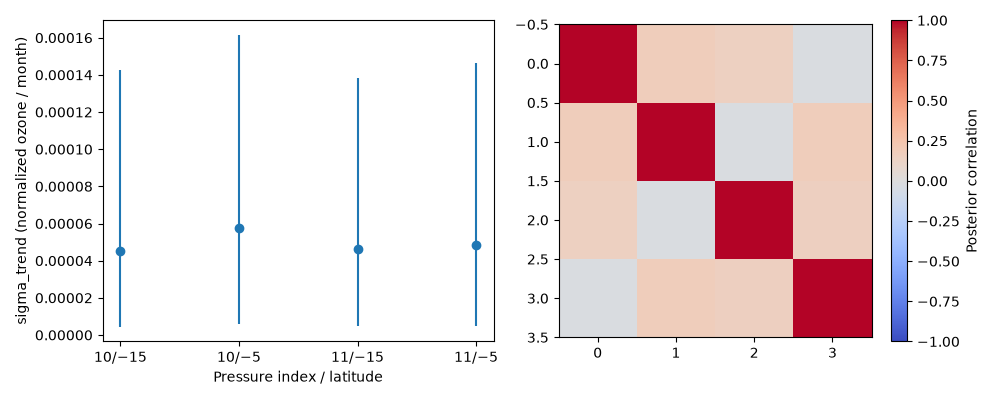

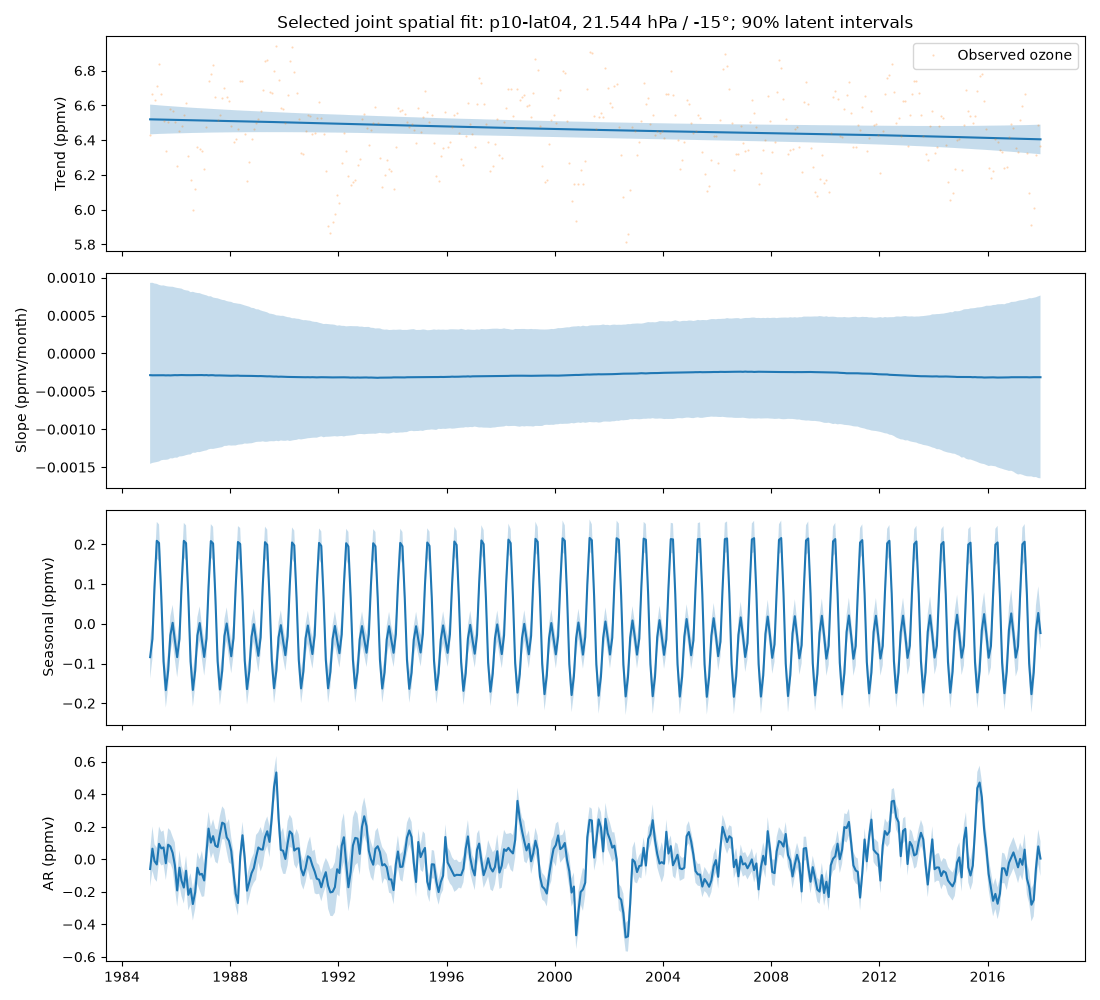

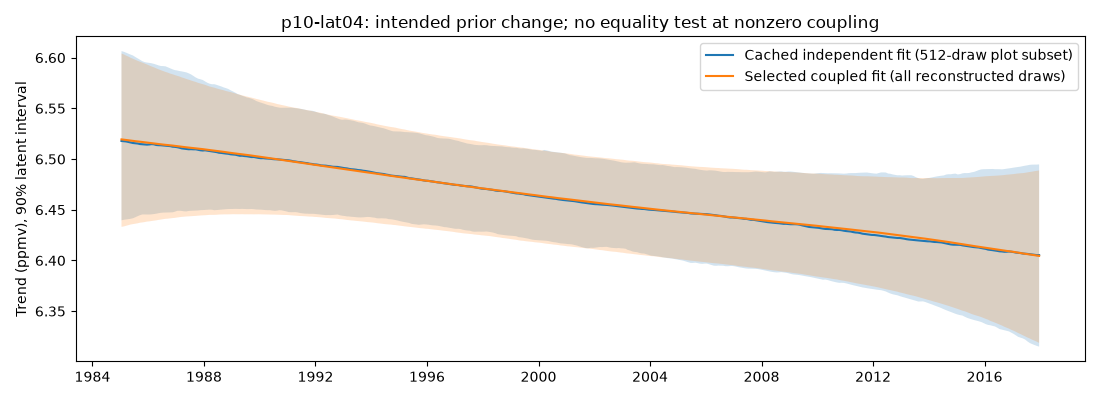

In [7]:
selected_bundle=Path.cwd()/"examples/modernization/spatial"
selected_evidence=json.loads((selected_bundle/"evidence.json").read_text())
for name, record in selected_evidence.items():
    assert hashlib.sha256((selected_bundle/name).read_bytes()).hexdigest()==record["sha256"]
selected_science=json.loads((selected_bundle/"05-selected-science.json").read_text())
print("Saved selected panels:",selected_science["panel_ids"])
print("Minimum scientific-output ESS:",selected_science["minimum_output_ess"])
for name in ["05-selected-field.png","05-selected-components-cell0.png","05-selected-independent-illustration.png"]:
    display(Image(filename=str(selected_bundle/name)))


## ENSO lag extension — its own stage06 selection

The predictor is **ENSO(t − lag)**: earlier ENSO predicts ozone. Only ENSO has a free lag. Its Gaussian field has mean zero, scale two months, and strict support **0 < lag < 12 months**. The lag and sigma-trend fields share fixed log-pressure/latitude lengths but are prior-independent. Other regressors keep their fixed inputs. Monthly interpolation uses one fixed observation window with complete predictor coverage; no extrapolation or proposal-dependent deletion.

CPU64 passes the four-cell joint Stan comparison (270 parameter/contrast/product and 812 reconstructed metrics) and a separate conditional multimodal quadrature fixture (26 metrics). Float32 is retained for research: interpolation is accurate, but joint numerical errors exceed the unchanged gate. GPU/final float32 lag inference remains pending. Cached synthetic results below are not a real-data lag estimate.

,cell,status,metrics,ESS,point_flags
0,0,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,203,"[15332.300567, 2944.611995]",[]
1,1,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,203,"[18801.229609, 3554.231203]",[]
2,2,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,203,"[17702.6496, 3472.922645]",[]
3,3,PRACTICALLY_CONSISTENT_AT_ACHIEVED_MC_PRECISION,203,"[15584.097414, 3154.872044]",[]


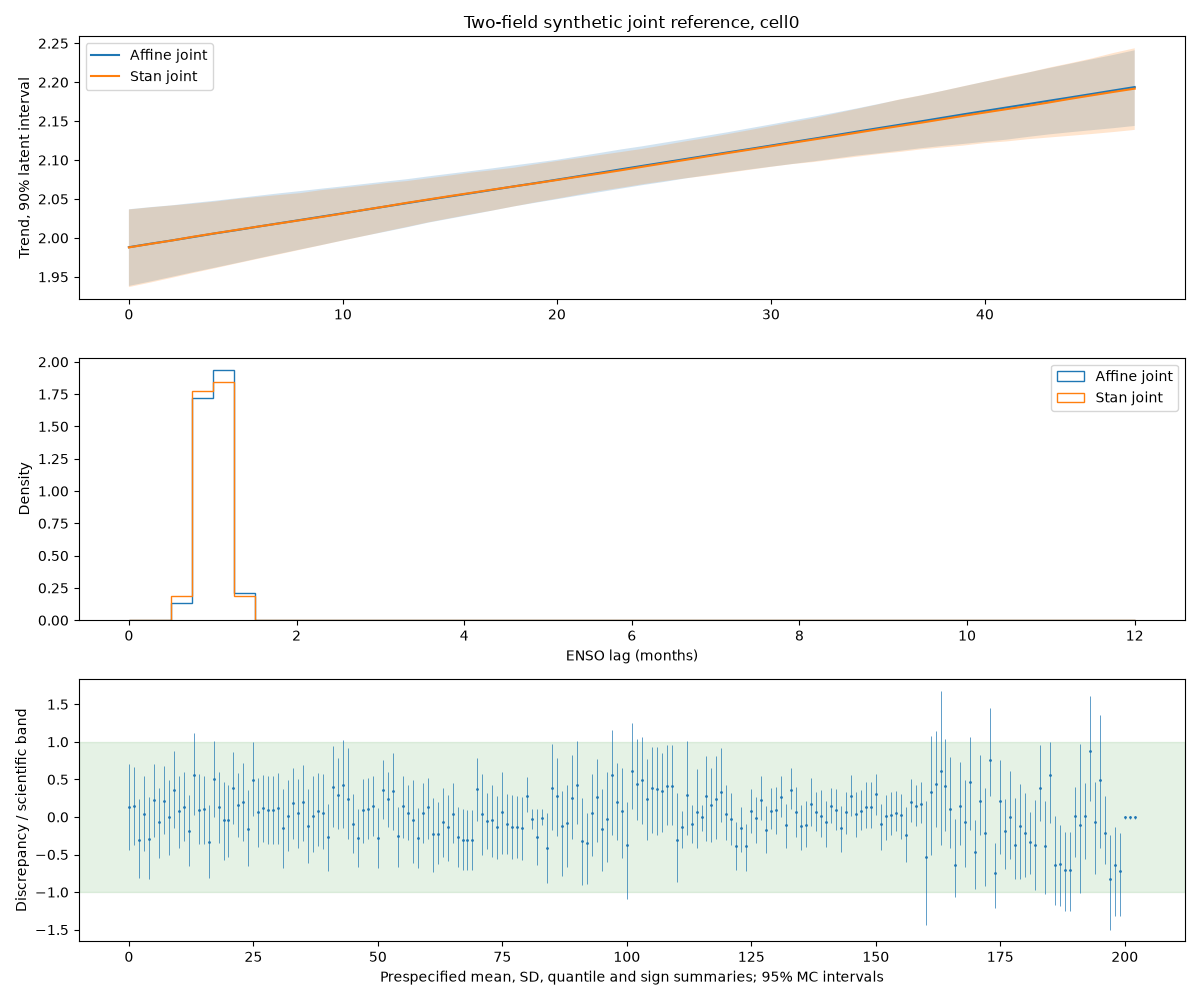

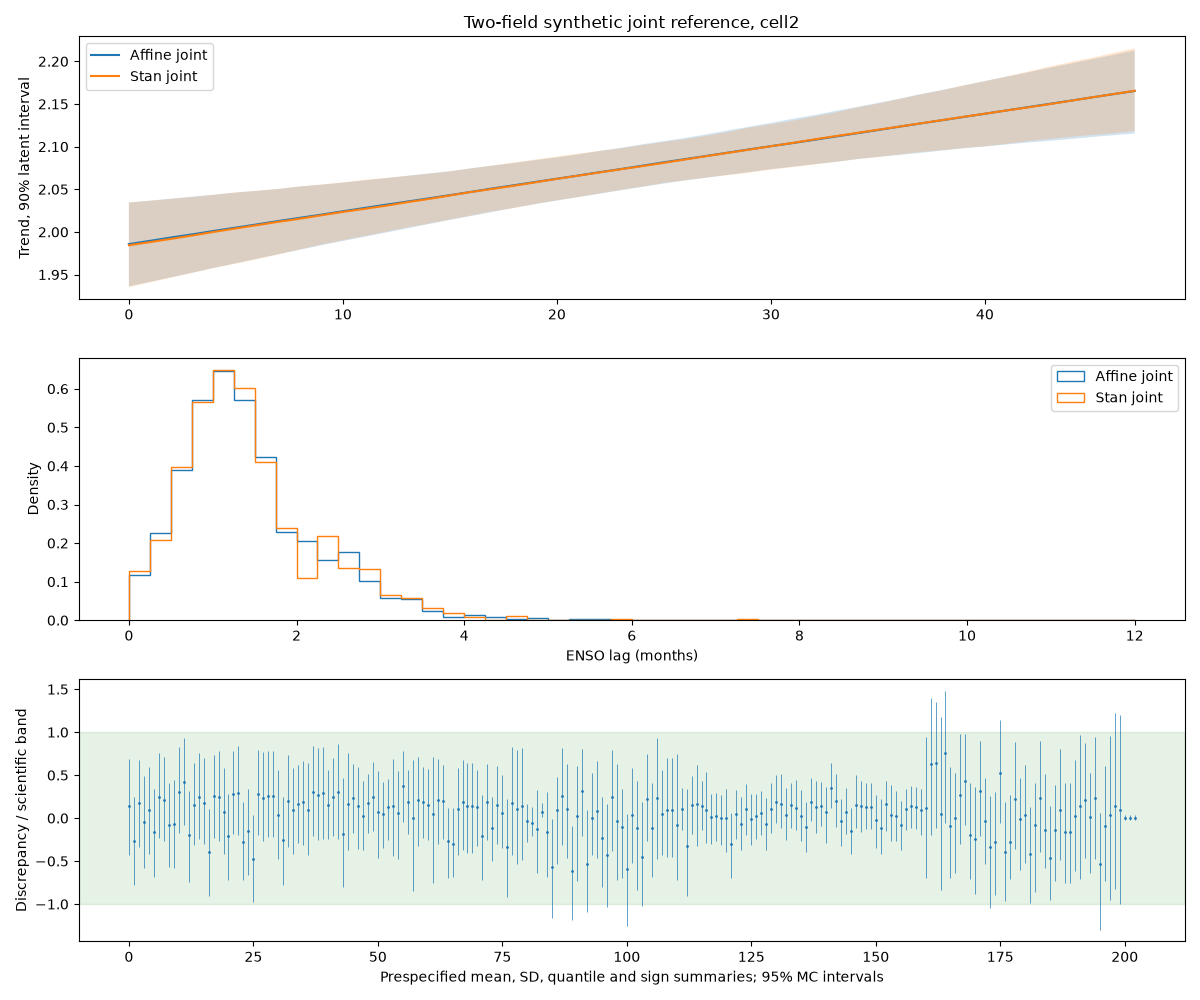

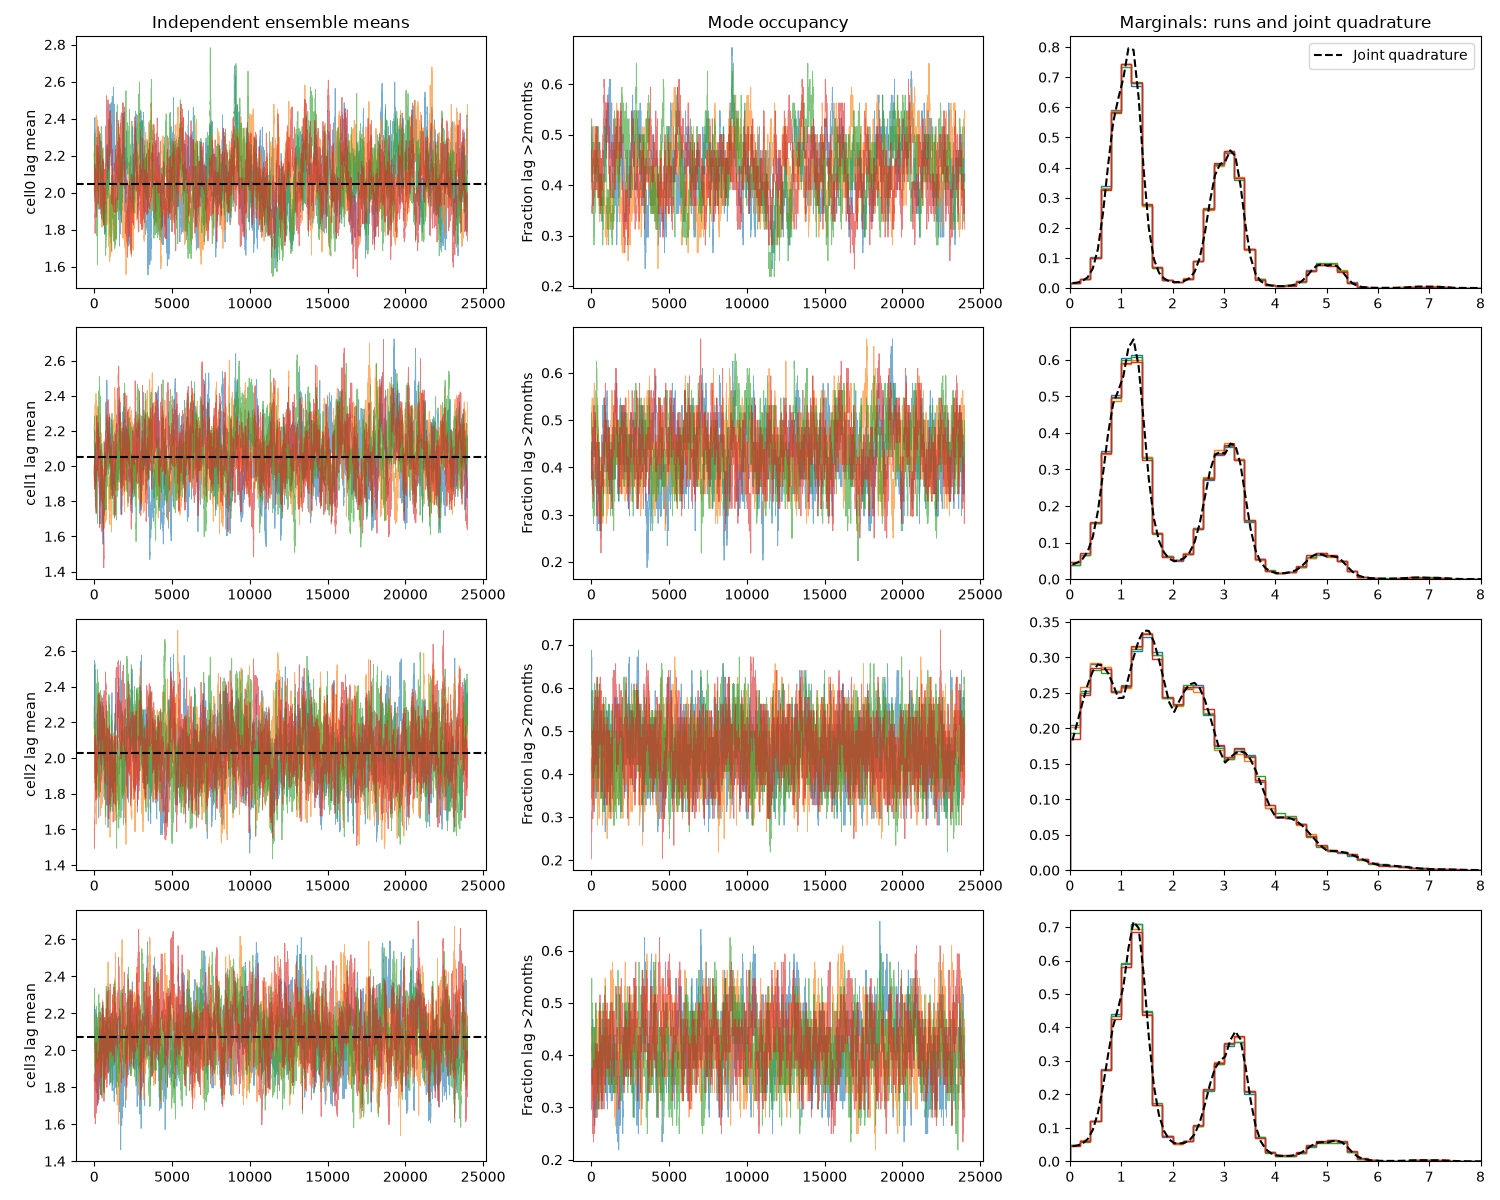

Cached synthetic joint results; weak cell remains broad; multimodal fixture fixes other hyperparameters explicitly.


In [8]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
lag_bundle=Path.cwd()/"examples/modernization/lag"
lag_evidence=json.loads((lag_bundle/"evidence.json").read_text())
for name,record in lag_evidence.items():
    assert hashlib.sha256((lag_bundle/name).read_bytes()).hexdigest()==record["sha256"]
rows=[]
for g in range(4):
    result=json.loads((lag_bundle/f"06-scientific-cell{g}.json").read_text())
    rows.append(dict(cell=g,status=result["status"],metrics=len(result["quantities"]),ESS=result["minimum_ess"],point_flags=result["point_flags"]))
display(pd.DataFrame(rows))
for name in ["06-scientific-cell0.png","06-scientific-cell2.png","trace-24000.png"]:
    display(Image(filename=str(lag_bundle/name)))
print("Cached synthetic joint results; weak cell remains broad; multimodal fixture fixes other hyperparameters explicitly.")


### Fresh lag API smoke, not a scientific fit

This uses only the first 12 months of the same four prepared panels, with full predictor history. It verifies interpolation, strict positive support, saved state continuation and the insufficient-diagnostics path. Four independent ensembles start near an optimized joint point; walkers are not independent chains. No trajectories are reconstructed from this intentionally short run.

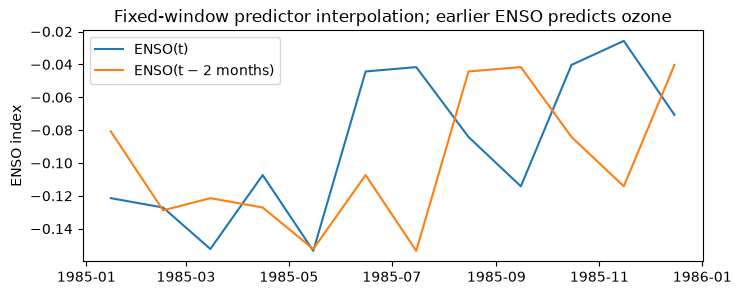

Frozen({'run': 4, 'draw': 6, 'walker': 40, 'cell': 4, 'parameter': 5}) INCONCLUSIVE
Fresh lag smoke complete; no scientific reconstruction or selected real fit.


In [9]:
from dataclasses import replace
import torch
from dlmmc import (MonthlyENSO, sample_enso_lag, resume_enso_lag,
                   load_enso_lag, diagnose_enso_lag)
source=np.loadtxt(lag_bundle/"ENSO_MEI_1950_201802.txt")
source_dates=pd.to_datetime(source[:,0],unit="D",origin="julian").to_numpy()
lag_predictor=MonthlyENSO.from_dates(source_dates,source[:,1],prepared.time,upper_lag=12)
lag_prior=replace(prior,mean=(0.,)*4,scale=(2.,)*4,field_unit="months",upper=12.)
interpolator=lag_predictor.bind(cells=4,dtype=torch.float64,device="cpu")
zero=interpolator(torch.zeros((1,4),dtype=torch.float64))
shift=interpolator(torch.full((1,4),2.,dtype=torch.float64))
np.testing.assert_array_equal(zero[0],prepared.regressors[:,:,prepared.regressor_names.index("ENSO")])
fig,ax=plt.subplots(figsize=(8,3))
ax.plot(prepared.time,zero[0,0],label="ENSO(t)")
ax.plot(prepared.time,shift[0,0],label="ENSO(t − 2 months)")
ax.set(ylabel="ENSO index",title="Fixed-window predictor interpolation; earlier ENSO predicts ozone")
ax.legend();plt.show()
with tempfile.TemporaryDirectory(prefix="dlmmc-lag-smoke-") as temporary:
    fit=sample_enso_lag(prepared,prior,lag_prior,lag_predictor,
        output_dir=Path(temporary)/"fit",half_walkers=20,runs=4,
        warmup=2,retained_sweeps=4,chunk_sweeps=2,seed=2026113301,
        wall_seconds=60,phase="pilot")
    fit=resume_enso_lag(fit.path,retained_sweeps=6,wall_seconds=60)
    restored=load_enso_lag(fit.path);posterior=restored.posterior()
    assert posterior.unconstrained.shape==(4,6,40,4,5)
    lag_values=12/(1+np.exp(-posterior.unconstrained.values[...,-1]))
    assert np.all((lag_values>0)&(lag_values<12))
    diagnostics=diagnose_enso_lag(restored)
    assert not diagnostics["eligible"]
    print(posterior.sizes,diagnostics["status"])
print("Fresh lag smoke complete; no scientific reconstruction or selected real fit.")


### New lag pilot → runtime estimate → separate selection

The actual four-panel timing pilot includes both fields and interpolation. Its short-window diagnostics remain inconclusive, with no walker-count winner. The full grid cannot fit current diagnostic memory on this laptop. Even a four-panel post-pilot fit requires its own explicit stage06 selection. Loading these estimates does not start that fit.

In [10]:
lag_runtime=json.loads((lag_bundle/"06-enso-lag-runtime-estimate.json").read_text())
display(pd.DataFrame([dict(panels=s["cells"],hours=np.array(s["execution_cost_range_seconds"])/3600,
                          diagnostic_GiB_lower=s["resources"]["diagnostic_working_bytes_lower_bound"]/2**30,
                          feasibility=s["current_feasibility"]) for s in lag_runtime["scenarios"]]))
print("New lag-inclusive pilot; compilation excluded, burn-in included. Mixing/scaling estimates are scenarios.")
lag_selection=Path.cwd().parent.parent/"reports/enso-lag-test-selection.json"
RUN_LAG_FIT=False
if RUN_LAG_FIT:
    raise RuntimeError("Use the selected stage06 driver only after its own explicit selection; notebook long fits stay disabled.")
print("Stage06 record present; verify matching scope before any external driver" if lag_selection.exists()
      else "Stage06 awaits explicit panel/region selection. Stage05 approval is not inherited.")


,panels,hours,diagnostic_GiB_lower,feasibility
0,4,"[0.862138, 1.882368]",1.129150,FEASIBLE_SMALL_SCOPE
1,8,"[1.477062, 3.522166]",3.204346,MEMORY_PRESSURE_POSSIBLE
2,324,"[442.898585, 1180.646227]",26024.658203,NOT_FEASIBLE_CURRENT_DIAGNOSTICS


New lag-inclusive pilot; compilation excluded, burn-in included. Mixing/scaling estimates are scenarios.
Stage06 record present; verify matching scope before any external driver


## Saved selected four-panel ENSO-lag result

The user separately selected **the same four panels with an initial two-hour cap**, after the new lag-inclusive pilot and runtime estimate. The result below is loaded from reviewed, checksum-verified saved output; opening the notebook does not repeat the fit. The region is 21.544/17.783 hPa and −15/−5° latitude, with natural log-pressure distances. Both fields remain prior-independent with shared fixed lengths.

The lag intervals describe the assumed ENSO(t − lag) model and its truncated Gaussian prior; they are not evidence of causality. The stage05 overlay compares two intentionally different coupled models. It is an illustration of the effect of inferring ENSO lag, not a backend-equivalence test. All scientific-output diagnostics, including lag/trend products and sampled trend-sign probabilities, were checked separately. Initial short/failed windows remain in the provenance record.

,panel,lag_q05_months,lag_median_months,lag_q95_months,output_ESS
0,p10-lat04,0.374345,1.788898,3.546740,5883.199400
1,p10-lat05,0.777061,1.772457,3.602936,5983.625415
2,p11-lat04,0.523276,1.481001,2.414706,5872.439394
3,p11-lat05,0.442149,1.327777,3.111083,5641.684462


Measured selected execution: {'sampling_including_burnin_seconds': 3341.960602487903, 'burnin_seconds': 543.8943308331072, 'retained_sampling_seconds': 2798.066271654796, 'initialization_seconds': 0.35327954194508493, 'initial_compile_cache_seconds': 0.09278699988499284, 'initial_disposable_warmup_seconds': 0.02439166698604822, 'resume_compile_disposable_seconds': 0.24925100011751056, 'initial_output_execution': {'status': 'OUTPUTS_COMPLETE_DIAGNOSTICS_RECORDED', 'eligible': True, 'wall_seconds': 245.47901391983032, 'compilation_seconds': 0.0, 'compilation_note': 'Eager Torch reconstruction; no JIT specialization', 'excluded_disposable_runtime_warmup_seconds': 1.1618896247819066, 'excluded_compile_disposable_seconds': 1.1618896247819066, 'post_compilation_seconds': 244.31712524872273, 'original_selected_budget_elapsed_seconds': 3973.4588539600372, 'selected_per_run': 2048, 'source_sha256': 'e5e2ef26447b3794e2857e552ada2ebf7d3bd69f2fcd612ed20a9149c4568654'}, 'review_inclusive_selected_e

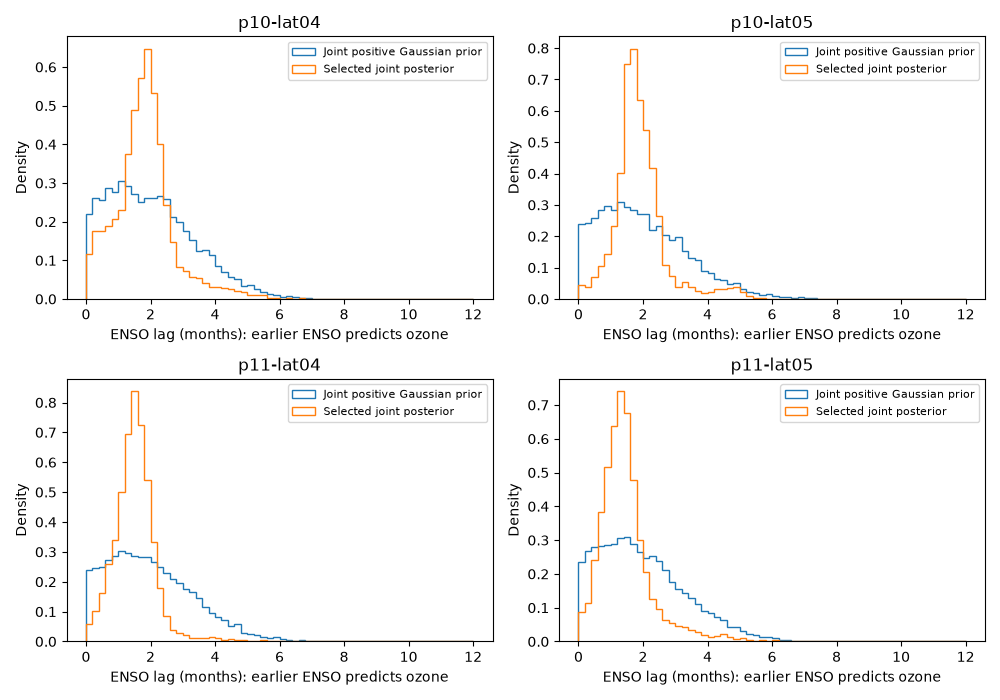

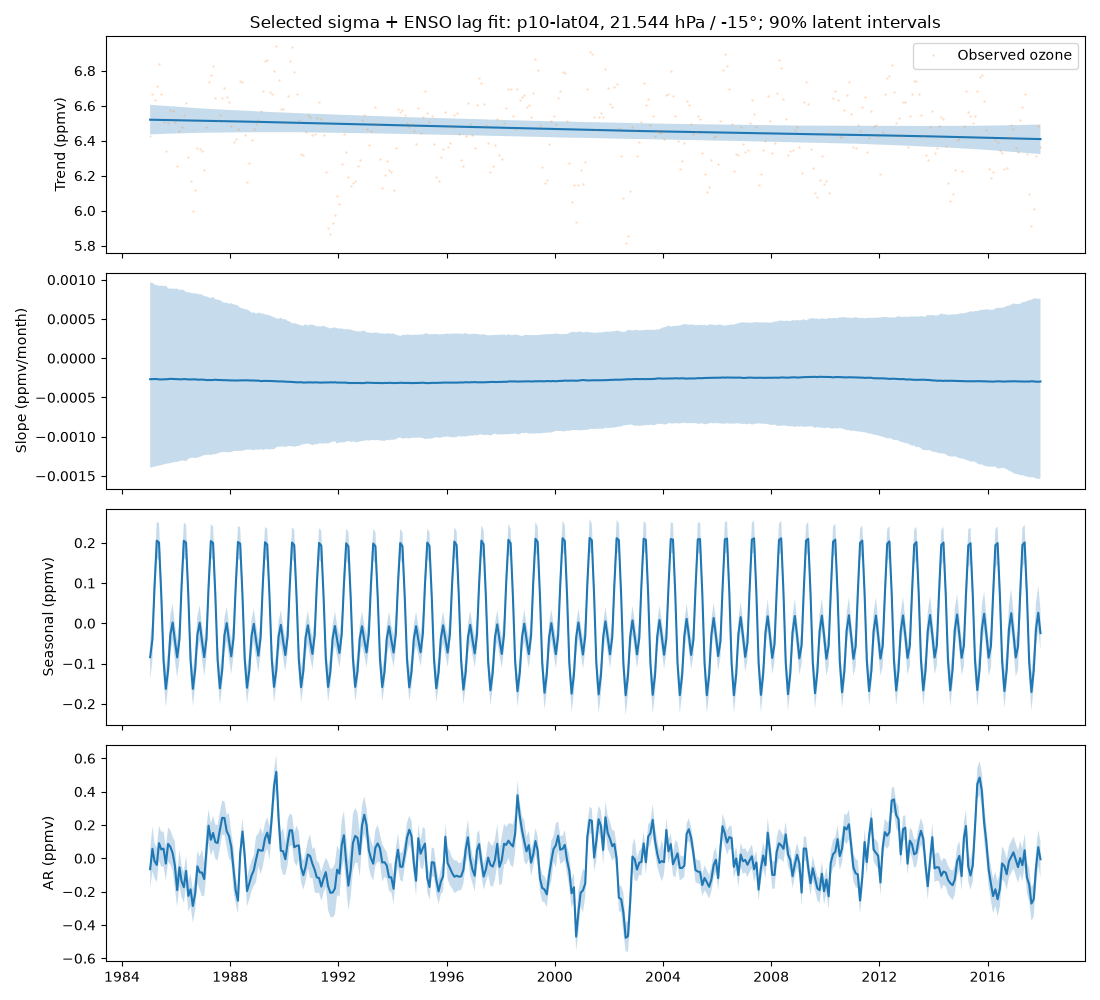

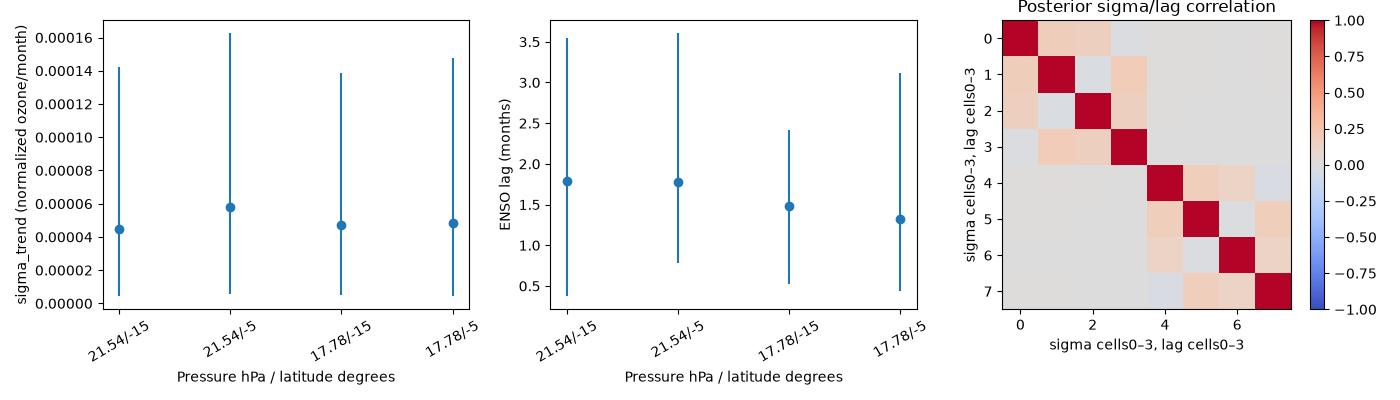

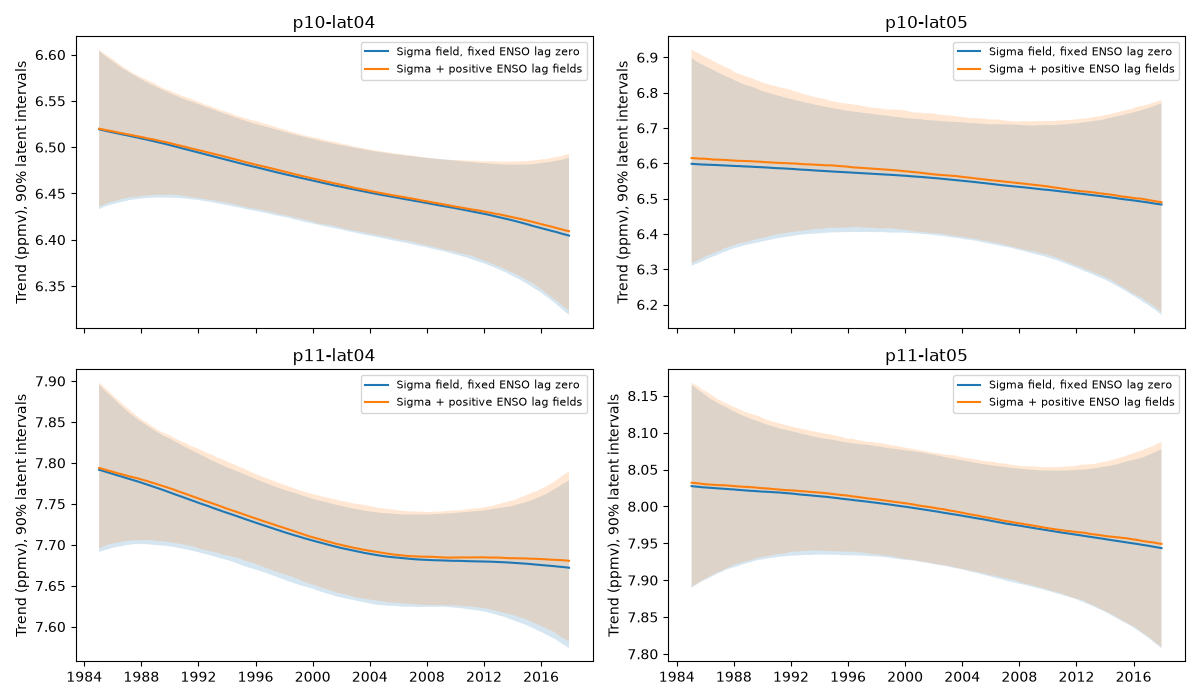

Saved scientific results; both notebook long-fit switches remain disabled.


In [11]:
lag_selected_bundle=Path.cwd()/"examples/modernization/lag"
lag_selected_evidence=json.loads((lag_selected_bundle/"evidence.json").read_text())
for name,record in lag_selected_evidence.items():
    assert hashlib.sha256((lag_selected_bundle/name).read_bytes()).hexdigest()==record["sha256"]
lag_science=json.loads((lag_selected_bundle/"06-selected-science.json").read_text())
lag_result=json.loads((lag_selected_bundle/"06-selected-result.json").read_text())
assert lag_result["status"]=="PARTIAL_LOCAL_PASS"
lag_q=np.array(lag_science["lag_quantiles"])
display(pd.DataFrame(dict(panel=lag_science["panel_ids"],lag_q05_months=lag_q[0],
    lag_median_months=lag_q[1],lag_q95_months=lag_q[2],
    output_ESS=lag_science["minimum_output_ess"])))
print("Measured selected execution:",lag_result["timing"])
for name in ["06-selected-lags.png","06-selected-components-cell0.png",
             "06-selected-fields.png","06-selected-stage05-illustration.png"]:
    display(Image(filename=str(lag_selected_bundle/name)))
print("Saved scientific results; both notebook long-fit switches remain disabled.")


## Named spatial specification in the current API

These objects specify Gaussian moments **before positive truncation**. Log-pressure is explicitly labeled; latitude is in degrees. Sigma uses normalized ozone units here. The lag prior uses months and ENSO(t − lag), with strict 0 < lag < 12 and fixed predictor coverage. The fields are prior-independent and share lengths. `fit_spatial(..., sigma_trend=sigma_spec, lags={"ENSO": lag_spec}, predictors={"ENSO": predictor})` is the current public fitting interface. This cell constructs specifications only; it does not bypass either stage-specific selection gate or launch a fit. Other/multiple lagged regressors remain unsupported.

In [12]:
from dlmmc import SpatialPrior, LagPrior
sigma_spec = SpatialPrior(mean=0, std=1e-4,
    correlation_lengths={"log_pressure": 0.163, "latitude": 8.49}, units="normalized")
lag_spec = LagPrior(mean=0, std=2, upper=12)
print(sigma_spec)
print(lag_spec)

SpatialPrior(mean=0, std=0.0001, correlation_lengths={'log_pressure': 0.163, 'latitude': 8.49}, units='normalized', coordinate_units={})
LagPrior(mean=0, std=2, upper=12, correlation_lengths=None)


## Composable models and matched MPS evidence

The fresh smoke fits above use component specifications. `Trend() + Harmonics((12, 6)) + Regression(dynamic=("ENSO",)) + AR(2)` additionally combines features that had no legacy preset. Named spatial priors/ENSO lag fields and independent versus joint acceptance remain separate choices. The separate stage-specific pilot/runtime/selection gates still apply; this section launches no new fit.

The saved November17 comparison below uses the same frozen five panels and 128 walkers /128 burn-in /256 retained, one ensemble. All six equivalent MPS likelihood/smoother cases match bitwise. The vanilla AR1 fit also replays exactly. This is a paired implementation-regression check, not new independent convergence evidence. Compilation/warmup are excluded from comparison timings and stored separately. After this saved comparison, the user explicitly removed the model-specific backend gate. No-AR GPU sampling is now available; both float32 density failures remain recorded, and CPU64 remains the reference. CUDA remains untested.

In [13]:
from pathlib import Path
import json, hashlib
composition_bundle = Path.cwd() / "examples/modernization/composition"
composition_manifest = json.loads((composition_bundle / "manifest.json").read_text())
for filename, expected in composition_manifest.items():
    assert hashlib.sha256((composition_bundle / filename).read_bytes()).hexdigest() == expected
composition_evidence = json.loads((composition_bundle / "comparison.json").read_text())
assert composition_evidence["fixed_bitwise_equal"]
assert all(row["parameter_draws_bitwise_equal"] and row["trend_outputs_bitwise_equal"]
           for row in composition_evidence["per_panel"])
print(composition_evidence["comparison"])
print(composition_evidence["timing"])
print("Retained no-AR float32 failures:", len(composition_evidence["precision_failures"]))

Frozen7478764 preset code versus self-contained component API; matching same-seed replay, not independent convergence replication
{'before': {'sampling_seconds': 5.149534502532333, 'fit_wall_seconds': 7.894867042079568, 'output_wall_seconds': 1.3860397920943797, 'end_to_end_excluding_compilation_warmup_seconds': 6.879155542002991, 'actual_process_seconds': 9.342271749861538}, 'after': {'sampling_seconds': 5.1621269977185875, 'fit_wall_seconds': 6.026094250148162, 'output_wall_seconds': 1.3251016668509692, 'end_to_end_excluding_compilation_warmup_seconds': 6.811979667050764, 'actual_process_seconds': 7.41249941685237}}
Retained no-AR float32 failures: 2
